<div style="border:1px solid #d8e2ef; border-radius:18px; padding:26px 30px; background:#ffffff;">
  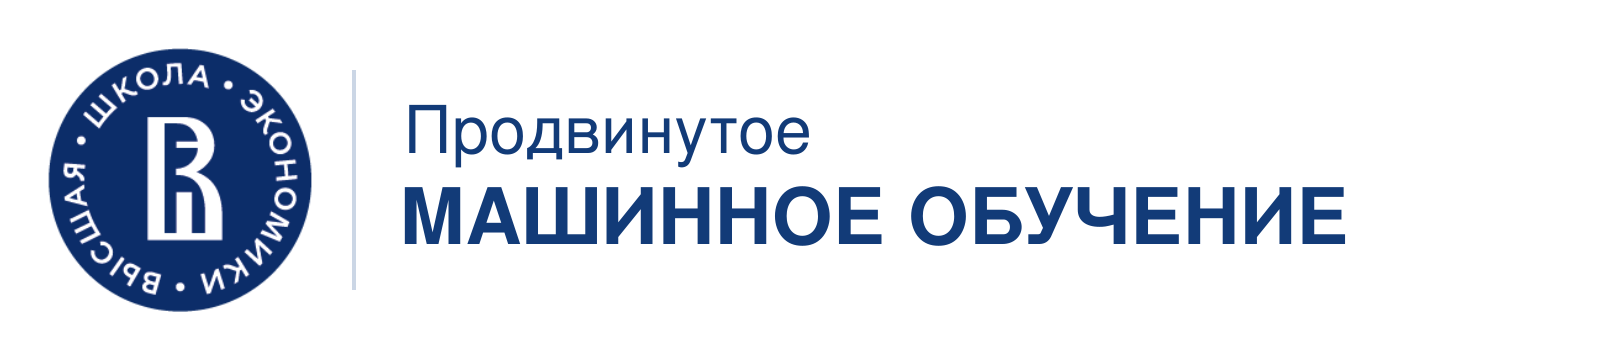

# Домашнее Задание №1
## Decision Trees
### Автор курса: Лапшина Анастасия (University of Maryland, College Park · НИУ ВШЭ)
### Credits for the homework: [ML курс Евгения Соколова](https://github.com/esokolov/ml-course-hse/blob/master/ml1-2026-spring/homework-practice/homework-practice-05-trees/homework-practice-05-trees.ipynb)
</div>


### Общая информация

**Дата выдачи:** \__.__.2026

**Мягкий дедлайн:** \__.__.2026, 23:59

**Жёсткий дедлайн:** \__.__.2026, 23:59

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов.

* При просроке в <= 24 часа оценка за ДЗ умножается на 0,7.

* При просроке в 24 < n <= 48 часов оценка за ДЗ умножается на 0,5.

* После жёсткого дедлайна работа не принимается.

Задание выполняется **самостоятельно**. «Похожие» решения считаются плагиатом: все задействованные студенты (в том числе те, у кого списали) получают 0 баллов.
Если вы пользовались внешними источниками (включая LLM), укажите это в блоке «Источники» в конце работы — с описанием того, что именно и для чего вы использовали. Это не штрафуется; скрытое использование — штрафуется нулём баллов.


**Устная защита.** Для проверки понимания кода и выводов студент может быть приглашён на
устную защиту. Если вы не можете объяснить ключевые части своего решения, работа
оценивается в 0 баллов независимо от пройденных тестов.


**ВАЖНО:** Код — это половина работы. Вторая половина — **выводы**. Формулировки вида «решающее дерево справилось плохо» без объяснения механизма приведет к снижению балла за задание. Хороший ответ отвечает на
вопрос «почему получилось именно так» и опирается на числа и графики, которые вы сами
получили. Все графики должны иметь подписанные оси, легенду и заголовок.


## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-01-Username.ipynb
* Модуль hw1_code.py

Username — ваша фамилия на латинице

### О задании

В процессе выполнения этого домашнего задания вы:

1. Попрактикуетесь использовать решающие деревья из `sklearn` для задачи классификации на простых двумерных датасетах, научитесь визуализировать разделяющие плоскости и распознавать переобучение.

2. Реализуете своё решающее дерево для задачи классификации и сравните его со стандартной имплементацией.

3. Исследуете влияние бэггинга на смещение и разброс.

In [174]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(0)

from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import classification_report
from sklearn.datasets import make_moons, make_circles, make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

sns.set(style='whitegrid')

import warnings
warnings.filterwarnings('ignore')

## Решающие деревья

### Визуализация (1 балл)

Рассмотрим три простых двумерных датасета, сгенерированных с помощью `make_moons`, `make_circles` и `make_classification`.

In [2]:
datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2,
                        class_sep=0.75, random_state=3, n_redundant=0)
]

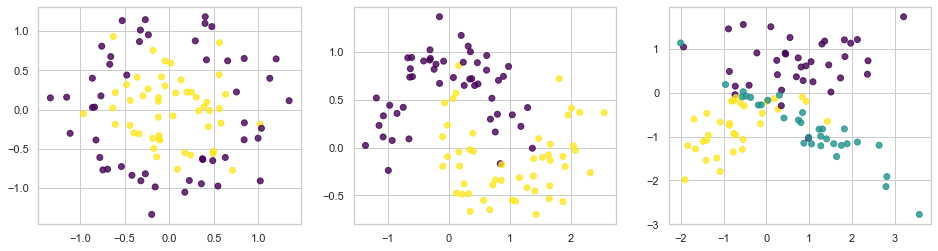

In [3]:
plt.figure(figsize=(16, 4))
for i, (x, y) in enumerate(datasets):
    plt.subplot(1, 3, i + 1)
    plt.scatter(x[:, 0], x[:, 1], c=y, cmap="viridis", alpha=0.8)

__Задание 1. (0.5 балла)__

Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделящие поверхности и посчитайте accuracy на обучающей и тестовой выборках. Прокомментируйте, в каких случаях и почему модель переобучается.

In [154]:
X, y = make_circles(noise=0.2, factor=0.5, random_state=42)
print(X.shape, y.shape)
print(np.unique(y, return_counts=True))
print(X[0], y[0])

(100, 2) (100,)
(array([0, 1], dtype=int32), array([50, 50]))
[-0.14065238 -0.6035081 ] 1


__Наблюдения (Комментарий):__ \
make_circles даёт $n=100$, $d=2$, классы по 50. Без шума класс 0 лежит на окружности радиуса 1, класс 1 на окружности радиуса factor $=0.5$.
$$\theta_k=\frac{2\pi k}{50},\qquad x=( \cos\theta_k,\ \sin\theta_k)\ \text{для класса 0},\qquad x=0.5(\cos\theta_k,\ \sin\theta_k)\ \text{для класса 1}$$
Потом к обеим координатам прибавляется $\varepsilon\sim\mathcal N(0,0.2^2)$. Первая строка $(-0.141,-0.604)$, метка 1.
$$(-0.141)^2=0.0199,\qquad (-0.604)^2=0.3648,\qquad r=\sqrt{0.3847}\approx 0.620$$
Без шума у класса 1 должно быть $r=0.5$. Разница $0.620-0.5=0.120$. До радиуса 1 остаётся $0.380$. Это не окружность, это уже выборка $S=\{(x_i,y_i)\}_{i=1}^{100}$. Распределение $P$ не восстанавливается.

In [155]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
print(X_train.shape, X_test.shape)
print(np.unique(y_train, return_counts=True))
print(np.unique(y_test, return_counts=True))

(70, 2) (30, 2)
(array([0, 1], dtype=int32), array([35, 35]))
(array([0, 1], dtype=int32), array([15, 15]))


__Наблюдения (Комментарий):__ \
Вывод (70, 2) и (30, 2), в каждой части 35 и 15 на класс. По лекции 1, часть 1, отделяет ожидаемый риск от эмпирического.
$$R_P(f)=\mathbb E_{(x,y)\sim P}\,\ell(f(x),y),\qquad \hat R_A(f)=\frac1{|A|}\sum_{i\in A}\ell(f(x_i),y_i)$$
Здесь $|A|=70$, $|A_{\mathrm{test}}|=30$, индексы не пересекаются. Сумма ещё не считается, потому что $f$ нет. Один сплит не является кроссвалидацией. Кроссвалидация усредняла бы $\hat R$ по нескольким фолдам.

In [156]:
tree = DecisionTreeClassifier()
print(tree.get_params())

{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'random_state': None, 'splitter': 'best'}


__Наблюдения (Комментарий):__ \
Вывод параметров: criterion=gini, max_depth=None, min_samples_leaf=1, min_samples_split=2, ccp_alpha=0. По лекции 2, часть 1, $\hat f(x)=\sum_m c_m\,1\{x\in R_m\}, c_m=\arg\max_k\hat p_k, \hat p_k=\frac{\#\{i\in R_m:y_i=k\}}{|R_m|}$ \
Прямоугольники $R_m$ режутся только стенкой $x_j\le s$. Стопы выключены, поэтому рекурсия может идти до $H=0$.

In [157]:
tree.fit(X_train, y_train)
print(tree.tree_.feature[0], tree.tree_.threshold[0])
print(tree.tree_.impurity[0], tree.tree_.n_node_samples[0], tree.tree_.value[0, 0])
left = X_train[:, 1] <= tree.tree_.threshold[0]
print(left.sum(), (~left).sum())
print(np.bincount(y_train[left]), np.bincount(y_train[~left]))

1 0.6205897629261017
0.5 70 [35. 35.]
58 12
[24 34] [11  1]


__Наблюдения (Комментарий):__ \
Вывод: признак 1, порог $0.621$, impurity $0.5$, 70 точек, классы 35 и 35, слева 58, справа 12, состоит из $[24,34]$ и $[11,1]$.
$$\hat p_0=\hat p_1=\frac{35}{70}=0.5,\qquad H(A)=1-0.5^2-0.5^2=0.5$$
Слева $x_1\le 0.621$.
$$H_L=1-\left(\frac{24}{58}\right)^2-\left(\frac{34}{58}\right)^2=1-\frac{576+1156}{3364}=1-\frac{1732}{3364}=\frac{1632}{3364}\approx 0.485$$
$$H_R=1-\left(\frac{11}{12}\right)^2-\left(\frac{1}{12}\right)^2=1-\frac{121+1}{144}=\frac{22}{144}\approx 0.153$$
Sklearn минимизирует взвешенную нечистоту.
$$Q=\frac{58}{70}\cdot 0.485+\frac{12}{70}\cdot 0.153\approx 0.402+0.026=0.428$$
$$Q_{\mathrm{лекц}}=-\frac{58}{70}H_L-\frac{12}{70}H_R\approx -0.428$$
$$\Delta Q=H(A)-Q=0.5-0.428=0.072$$
Порог $0.621$ есть середина двух соседних разных значений признака 1, как в лекции 2, части 3, $s=(v_{(t)}+v_{(t+1)})/2$. Разрез ставится, потому что $\Delta Q>0$ и $70\ge 2$.

In [159]:
print(tree.score(X_train, y_train))
print(tree.get_depth(), tree.get_n_leaves())
print(tree.score(X_test, y_test))
print((tree.predict(X_test) != y_test).sum())

1.0
6 15
0.7333333333333333
8


train $1.0$, глубина 6, листьев 15, test $0.7333$, ошибок 8. Потеря здесь 0 1, accuracy это единица минус эмпирический риск.
$$\hat R_A=\frac1{70}\sum_{i\in A}1\{\hat f(x_i)\ne y_i\}=0,\qquad \mathrm{acc}_A=1-\hat R_A=1$$
$$\hat R_{A_{\mathrm{test}}}=\frac{8}{30}\approx 0.267,\qquad \mathrm{acc}_{A_{\mathrm{test}}}=\frac{22}{30}\approx 0.733,\qquad \mathrm{gap}=\hat R_{A_{\mathrm{test}}}-\hat R_A=0.267$$
Ноль на обучении следует из стопов. При $H=0$ лист отвечает единственным классом, а min_samples_leaf=1 разрешает лист из одной точки. Поэтому $\mathrm{acc}_A=1$ не оценка качества. $\hat R_P$ не даёт. Есть только 30 отложенных строк, это оценка $R_P$, не сам $R_P$.

В лекции 1, части 2, раскладывается ошибка на шум, bias и variance. На учебных точках bias нулевой, потому что $\hat R_A=0$. Gap $0.267$ и 15 листьев при глубине 6 значат, что часть $R_m$ подогнана под $\varepsilon$, а не под два кольца. Осевой предикат $x_j\le s$ окружность не повторяет, дерево собирает её лесенкой. Поменять несколько строк в $A$, порог $0.621$ может стать другим. Это и есть большой variance при выключенных стопах.

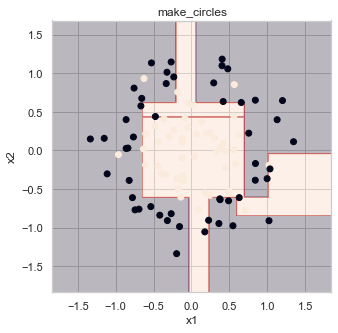

In [65]:
x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = tree.predict(grid).reshape(xx.shape)
plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, zz, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("make_circles")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

1.0
5 9
0.9333333333333333
2


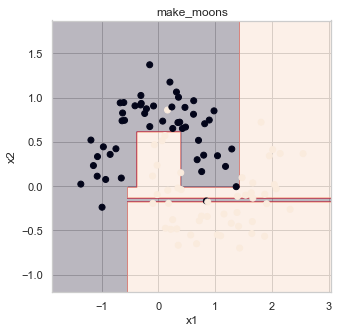

In [167]:
X, y = make_moons(noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)
print(tree.score(X_train, y_train))
print(tree.get_depth(), tree.get_n_leaves())
print(tree.score(X_test, y_test))
print((tree.predict(X_test) != y_test).sum())
x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = tree.predict(grid).reshape(xx.shape)
plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, zz, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("make_moons")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

1.0
9 18
0.7
9


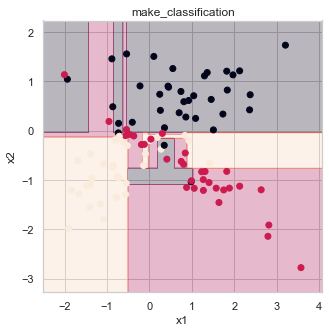

In [166]:
X, y = make_classification(n_classes=3, n_clusters_per_class=1, n_features=2, class_sep=0.75, random_state=3, n_redundant=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)
print(tree.score(X_train, y_train))
print(tree.get_depth(), tree.get_n_leaves())
print(tree.score(X_test, y_test))
print((tree.predict(X_test) != y_test).sum())
x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = tree.predict(grid).reshape(xx.shape)
plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, zz, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("make_classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

__Ответ:__ \
**Общее для трёх датасетов.** \
В каждом $n=100$, $d=2$, сплит test_size=0.3 даёт $|A|=70$ и $|A_{\mathrm{test}}|=30$. Потеря 0 1, accuracy это единица минус эмпирический риск.
$$\hat R_A(f)=\frac1{|A|}\sum_{i\in A}1\{\hat f(x_i)\ne y_i\},\qquad \mathrm{acc}=1-\hat R$$
Параметры одни. criterion=gini, max_depth=None, min_samples_leaf=1, min_samples_split=2, ccp_alpha=0. Класс функций из лекции 2, части 1, $\hat f(x)=\sum_m c_m\,1\{x\in R_m\}, c_m=\arg\max_k\hat p_k$ \
Стенка только $x_j\le s$, порог это середина соседних значений. Лист ставится при $H=0$. Поэтому на всех трёх обучении вывод обязан дать $\mathrm{acc}_A=1$, что на выходе мы и получили. $\hat R_A=0$ не качество модели, а следствие стопов.

**Круги.** \
train $1.0$, глубина 6, листьев 15, test $0.7333$, ошибок 8.
$$\hat R_{A_{\mathrm{test}}}=\frac{8}{30}\approx 0.267,\qquad \mathrm{gap}=0.267-0=0.267$$
Корень уже считали. Признак 1, $s=0.621$, $H(A)=0.5$, слева 58 точек $[24,34]$, справа 12 точек $[11,1]$, $\Delta Q=0.072$. Дальше рекурсия до $H=0$. На картинке кольцо собрано из прямоугольников. Серая область снаружи, бежевый прямоугольник в центре, вертикальная полоса около $x_1=0$ от верха до низа и горизонтальные коридоры около $x_2=0.4$ и $x_2=-0.2$. Выступ вправо около $x_1=1$ держится на нескольких точках. Осевой $R_m$ окружность радиуса 0.5 и 1 не повторяет, дерево добирает лесенкой и по дороге вырезает точки, сдвинутые noise=0.2. Поменять несколько строк в $A$, порог $0.621$ может стать другим.

**Луны.** \
train $1.0$, глубина 5, листьев 9, test $0.9333$, ошибок 2.
$$\hat R_{A_{\mathrm{test}}}=\frac{2}{30}\approx 0.067,\qquad \mathrm{gap}=0.067$$
Ошибок в $8/2=4$ раза меньше, чем на кругах, листьев 9 вместо 15, глубина на 1 меньше. На картинке левый полумесяц лежит в серой области, правый в бежевой. Разделение держится на горизонтали около $x_2=0$ и короткой вертикали около $x_1=0$. Тонкая щель около $x_2=0$ есть, отдельных островов мало. Форма совместима с $x_j\le s$, шум 0.2 реже требует листа из одной точки. Переобучение слабое, потому что gap равен 0.067, а граница почти совпадает с двумя полумесяцами.

**Три класса.** \
train $1.0$, глубина 9, листьев 18, test $0.7$, ошибок 9.
$$\hat R_{A_{\mathrm{test}}}=\frac{9}{30}=0.3,\qquad \mathrm{gap}=0.3$$
Здесь $K=3$, поэтому $H=1-\hat p_0^2-\hat p_1^2-\hat p_2^2$
До $H=0$ нужно больше разрезов, отсюда глубина 9 и 18 листьев, больше, чем 15 на кругах. На картинке три цвета режутся вертикальными полосами слева и горизонтальными лентами справа. На стыке около $(0.4,-0.4)$ сидит отдельный тёмный прямоугольник, который держится на нескольких учебных точках. Облака пересекаются при class_sep=0.75, точки разных классов перемешаны, лист под одну такую точку на тесте уже не работает.

В связи с этим переобучение есть там, где $\hat R_A=0$, а $\hat R_{A_{\mathrm{test}}}$ заметно больше нуля, и на картинке есть узкий $R_m$ под отдельные точки. На кругах gap равен 0.267 при 15 листьях, кольцо собрано лесенкой. На трёх классах gap равен 0.3 при 18 листьях, стык облаков разрезан на мелкие прямоугольники. На лунах gap равен 0.067 при 9 листьях, граница почти совпадает с формой, переобучение слабое. Во всех трёх случаях ноль на обучении даёт min_samples_leaf=1. Bias на учебных точках нулевой, variance большой, потому что при смене нескольких строк в $A$ стенка $x_j\le s$ сдвигается.

__Задание 2. (0.5 балла)__

Выберите один датасет из предыдущего задания и исследуйте на его примере влияние на итоговое качество двух гиперпараметров (любых на ваш выбор) одновременно. Для каждой пары значений посчитайте accuracy на обучающей и тестовой выборках и сохраните результаты в таблицу.

Визуализируйте зависимость качества на тестовой выборке от значений выбранных вами гиперпараметров. При каких значениях наблюдается лучшее соотношение разброса и смещения? Почему вы сделали такой вывод?

In [68]:
depths = [1, 2, 3, 5, 8, None] # 6
leaves = [1, 2, 4, 8, 12] # 5

In [69]:
rows = []
for d in depths:
    for m in leaves:
            tree = DecisionTreeClassifier(max_depth=d, min_samples_leaf=m, random_state=0)
            tree.fit(X_train, y_train)
            rows.append({
                "max_depth": str(d),
                "min_samples_leaf": m,
                "acc_train": tree.score(X_train, y_train),
                "acc_test": tree.score(X_test, y_test),
                "depth_fact": tree.get_depth(),
                "n_leaves": tree.get_n_leaves(),
            })
table = pd.DataFrame(rows)
print(table.to_string(index=False))

max_depth  min_samples_leaf  acc_train  acc_test  depth_fact  n_leaves
        1                 1   0.657143  0.666667           1         2
        1                 2   0.657143  0.666667           1         2
        1                 4   0.657143  0.666667           1         2
        1                 8   0.657143  0.666667           1         2
        1                12   0.657143  0.666667           1         2
        2                 1   0.842857  0.900000           2         4
        2                 2   0.842857  0.900000           2         4
        2                 4   0.842857  0.900000           2         4
        2                 8   0.842857  0.900000           2         4
        2                12   0.842857  0.900000           2         4
        3                 1   0.871429  0.866667           3         7
        3                 2   0.842857  0.866667           3         7
        3                 4   0.842857  0.900000           3         6
      

__Наблюдения (Комментарий):__ \
Беру круги из задания 1, те же $|A|=70$ и $|A_{\mathrm{test}}|=30$. Два стопа из лекции 2, части 4. max_depth=d запрещает вопрос, если уровень уже равен $d$. min_samples_leaf=m запрещает разрез, если в ребёнке будет меньше $m$ точек. Джини тот же, $H=1-\hat p_0^2-\hat p_1^2, Q=\frac{N_L}{N}H_L+\frac{N_R}{N}H_R$. None значит потолка нет. Сетка $6\cdot 5=30$ пар. Accuracy это $1-\hat R$ при индикаторе несовпадения.
При $d=1$ все пять $m$ совпали, train $46/70$, test $20/30$, листьев 2.
$$\hat R_A=\frac{24}{70}\approx 0.343,\qquad \hat R_{A_{\mathrm{test}}}=\frac{10}{30}\approx 0.333$$
Один разрез делит 70 точек на куски больше 12, поэтому $m$ не срабатывает. Кольцо одним вопросом не отделяется, bias большой.
При $d=2$ снова все $m$ совпали, train $59/70$, test $27/30$, глубина 2, листьев 4.
$$\hat R_A=\frac{11}{70}\approx 0.157,\qquad \hat R_{A_{\mathrm{test}}}=\frac{3}{30}=0.1,\qquad \mathrm{gap}=0.1-0.157=-0.057$$
При $d=\mathrm{None}$ и $m=1$ train $70/70$, test $22/30$, глубина 9, листьев 18.
$$\hat R_A=0,\qquad \hat R_{A_{\mathrm{test}}}=\frac{8}{30}\approx 0.267,\qquad \mathrm{gap}=0.267$$
Между ними при $m=1$ train растёт с глубиной. При $d=5$ train равен $65/70$, листьев 13, test равен $22/30$. При $d=8$ train равен $69/70$, листьев 17, test равен $23/30$. Если $m=8$ или $m=12$, depth_fact падает до 3 даже при потолке 5, 8 и None. Лист из 8 точек сам обрезает дерево.

In [70]:
pivot_test = table.pivot(index="min_samples_leaf", columns="max_depth", values="acc_test")
print(pivot_test)

max_depth                1    2         3         5         8      None
min_samples_leaf                                                       
1                 0.666667  0.9  0.866667  0.733333  0.766667  0.733333
2                 0.666667  0.9  0.866667  0.800000  0.800000  0.800000
4                 0.666667  0.9  0.900000  0.866667  0.866667  0.866667
8                 0.666667  0.9  0.900000  0.900000  0.900000  0.900000
12                0.666667  0.9  0.900000  0.900000  0.900000  0.900000


__Наблюдения (Комментарий):__ \
Клетка это $\mathrm{acc}_{\mathrm{test}}(m,d)$. Столбец $d=1$ весь равен $20/30$. Столбец $d=2$ весь равен $27/30$. Это максимум. Строка $m=1$ после $d=2$ падает. Строки $m=8$ и $m=12$ держат $0.9$, потому что фактическая глубина там 2 или 3.

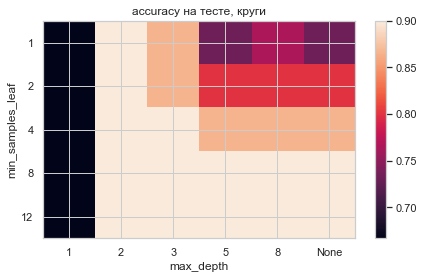

In [71]:
plt.figure(figsize=(7, 4))
plt.imshow(pivot_test.values, aspect="auto")
plt.xticks(range(len(pivot_test.columns)), pivot_test.columns)
plt.yticks(range(len(pivot_test.index)), pivot_test.index)
plt.xlabel("max_depth")
plt.ylabel("min_samples_leaf")
plt.title("accuracy на тесте, круги")
plt.colorbar()
plt.show()

__Ответ:__ \
Столбец $d=1$ тёмный, столбец $d=2$ светлый, правый верхний угол снова тёмный. Светлая клетка это высокий test.
Лучшая пара $d=2$, $m=1$. Test $27/30$, gap равен $-0.057$, листьев 4. Двух вопросов $x_j\le s$ хватает, чтобы отделить кольца лучше, чем одним, и не хватает, чтобы вырезать лист под шум noise=0.2. При $d=1$ тест равен $10/30$, bias большой. При None и $m=1$ тест равен $8/30$ при 18 листьях, variance большой. $m=8$ даёт тот же test только потому, что глубина падает до 3. Из клеток с test $0.9$ самая короткая это глубина 2.

### Решающие деревья своими руками (6 баллов)

Итак, пришло время реализовать свой класс для обучения решающего дерева.

__Задание 3. (1.5 балла)__

Реализуйте функцию `find_best_split` из модуля `hw1_code.py` согласно алгоритму, расказанному на лекции; её сигнатура и докстринг с дополнительными требованиями и указаниями прописаны в файле.

Напоминаем, что под критерием Джини подразумевается следующая функция качества разбиения:

$$
Q(R, R_l, R_r) = -\frac{|R_l|}{|R|} H(R_l) - \frac{|R_r|}{|R|} H(R_r),
$$

где $R$ - множество объектов, $R_l$ и $R_r$ - объекты, попавшие в левое и правое поддерево соответственно.

Функция неоднородности Джини для множества $R$ определяется как

$$
H(R) = 1 - \sum_{k=1}^{K} p_k^2,
$$

где $p_k$ - доля объектов класса $k$ в множестве $R$, а $K$ - число различных классов в текущем узле.

Замечание: при $K=2$ формула сводится к бинарному случаю $H(R)=1-p_0^2-p_1^2$, где $p_1$ и $p_0$ $-$ доля объектов классов $1$ и $0$ соответственно.


In [168]:
def find_best_split(feature_vector, target_vector):
    feature_vector = np.asarray(feature_vector, dtype=float)
    target_vector = np.asarray(target_vector)
    order = np.argsort(feature_vector, kind="mergesort")
    x = feature_vector[order]
    y = target_vector[order]
    different = x[1:] != x[:-1]
    thresholds = ((x[1:] + x[:-1]) / 2)[different]
    if thresholds.size == 0:
        return np.array([]), np.array([]), None, None
    classes = np.unique(y)
    y01 = (y == classes[-1]).astype(float)
    n = y01.size
    prefix_pos = np.cumsum(y01)
    total_pos = prefix_pos[-1]
    left_end = np.where(different)[0]
    n_left = left_end + 1
    n_right = n - n_left
    pos_left = prefix_pos[left_end]
    pos_right = total_pos - pos_left
    p1_l = pos_left / n_left
    p1_r = pos_right / n_right
    H_left = 1.0 - (1.0 - p1_l) ** 2 - p1_l ** 2
    H_right = 1.0 - (1.0 - p1_r) ** 2 - p1_r ** 2
    ginis = -(n_left / n) * H_left - (n_right / n) * H_right
    best = np.argmax(ginis)
    return thresholds, ginis, thresholds[best], ginis[best]

__Проверка__ на $x=(1,2,8,9)$, $y=(0,0,1,1)$.

In [169]:
x_check = np.array([1., 2., 8., 9.])
y_check = np.array([0, 0, 1, 1])
print(find_best_split(x_check, y_check))

(array([1.5, 5. , 8.5]), array([-0.33333333, -0.        , -0.33333333]), 5.0, -0.0)


__Наблюдения (Комментарий):__ \
Вывод пороги $[1.5,\ 5,\ 8.5]$, критерии $[-1/3,\ 0,\ -1/3]$, лучший порог $5$, лучший $Q=0$. В лекции 2, часть 3, сначала сортируется признак. argsort с mergesort даёт $x_{(1)}\le x_{(2)}\le \cdots\le x_{(n)}$ \
На этих четырёх порядок уже такой, $n=|R|=4$. different оставляет только соседние разные значения. Если два объекта имеют один $x$, середина между ними никого не разводит, и такой порог не кандидат. Докстринг запрещает пустого ребёнка, поэтому крайние пороги тоже не берутся вне отрезка между первым и последним разным значением.
Порог есть середина соседей.
$$s=\frac{x_{(t)}+x_{(t+1)}}{2}$$
$$s_1=\frac{1+2}{2}=1.5,\qquad s_2=\frac{2+8}{2}=5,\qquad s_3=\frac{8+9}{2}=8.5$$
Если все $x$ равны, thresholds пустой, функция возвращает пустые массивы и None. Докстринг это разрешает.
Метки сводятся к 0 и 1, докстринг просит только бинарный случай. В лекции 2, часть 2 описано так, что $H(R)=1-p_0^2-p_1^2, p_1=\frac{\#\{y=1\}}{|R|},\qquad p_0=1-p_1$
cumsum считает единицы слева без цикла. Для конца слева на индексе $t$ с нуля $|R_L|=t+1, |R_R|=n-|R_L|$.
На $s=5$ слева $(1,2)$ с метками $(0,0)$, справа $(8,9)$ с метками $(1,1)$.
$$H_L=1-1^2-0^2=0,\qquad H_R=1-0^2-1^2=0$$
Критерий задания максимизируется, знак минус уже стоит в формуле.
$$Q(R,R_L,R_R)=-\frac{|R_L|}{|R|}H_L-\frac{|R_R|}{|R|}H_R$$
$$Q(5)=-\frac{2}{4}\cdot 0-\frac{2}{4}\cdot 0=0$$
На $s=1.5$ слева одна точка класса 0, $H_L=0$. Справа три точки, классы $0,1,1$.
$$p_1=\frac23,\qquad H_R=1-\left(\frac13\right)^2-\left(\frac23\right)^2=\frac49$$
$$Q(1.5)=-\frac14\cdot 0-\frac34\cdot\frac49=-\frac13$$
На $s=8.5$ симметрично, тоже $-1/3$. argmax берёт наибольший $Q$. При равных $Q$ берётся первый, а пороги отсортированы, поэтому это меньший $s$. Здесь максимум один, $s=5$, $Q=0$. Оба ребёнка чистые.

__Задание 4. (0.75 балл)__

Загрузите датасет [Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance). Поработайте с данными: создайте бинарный признак `pass`, который будет равен единице, если итоговая оценка `G3` не меньше $10$, и нулю в противном случае. Затем выберите пять числовых признаков, среди которых должны быть как очень информативные, так и потенциально неинформативные. Коротко обоснуйте свой выбор.

Для каждого из выбранных признаков постройте график зависимости критерия Джини от возможного порога разделения. Отобразите все пять кривых на одном рисунке.

Для каждого из выбранных признаков дополнительно визуализируйте зависимость
"значение признака - класс (0/1)".

> Можно, например, построить scatter-график, где по оси X - значение признака, а по оси Y - бинарный признак `pass` (при необходимости используйте небольшой jitter по оси Y и/или прозрачность alpha, чтобы лучше видеть плотность точек); или использовать эквивалентную по смыслу визуализацию (например, `seaborn.stripplot` / `swarmplot`), из которой видно, как распределены значения признака внутри каждого класса.

In [74]:
df = pd.read_csv("student-mat.csv", sep=";")
print(df.shape)
print(df["G3"].head(10).tolist())

(395, 33)
[6, 6, 10, 15, 10, 15, 11, 6, 19, 15]


__Наблюдения (Комментарий):__ \
Вывод (395, 33) и первые десять G3 равны $6,6,10,15,10,15,11,6,19,15$. Строк $n=395$. G3 это итоговая оценка, из неё делается метка, а не признак.

In [79]:
df["pass"] = (df["G3"] >= 10).astype(int)
print(df[["G3", "pass"]].head(10))
print("сдало", int(df["pass"].sum()), "из", len(df))

   G3  pass
0   6     0
1   6     0
2  10     1
3  15     1
4  10     1
5  15     1
6  11     1
7   6     0
8  19     1
9  15     1
сдало 265 из 395


__Наблюдения (Комментарий):__ \
Вывод: $6$ даёт $0$, $10$ даёт $1$, сдало $265$ из $395$. Десятка здесь не порог дерева. Это правило метки $y_i=1\{G3_i\ge 10\}$
Нулей $395-265=130$, единиц $265$. Метка не константа. До любого разреза доля и нечистота корня,по лекции 2, часть 2, $p_1=\frac{265}{395}\approx 0.671, p_0=1-p_1\approx 0.329$, 
$H(R)=1-p_0^2-p_1^2\approx 1-0.108-0.450=0.442$ \
Хороший признак должен поднять $Q$ сильно выше $-0.442$.

In [81]:
y = df["pass"].values
nums = df.select_dtypes(include="number").columns.drop(["G3", "pass"])
for name in nums:
    thresholds, ginis, s_best, q_best = find_best_split(df[name].values, y)
    print(name, len(thresholds), s_best, round(q_best, 4))

age 7 17.5 -0.4301
Medu 4 3.5 -0.4357
Fedu 4 1.5 -0.4375
traveltime 3 1.5 -0.4404
studytime 3 2.5 -0.4378
failures 3 0.5 -0.3945
famrel 4 3.5 -0.4404
freetime 4 2.5 -0.4394
goout 4 3.5 -0.4249
Dalc 4 1.5 -0.4379
Walc 4 3.5 -0.4403
health 4 1.5 -0.4379
absences 33 13.5 -0.4314
G1 16 10.5 -0.2477
G2 16 9.5 -0.1407


In [89]:
# Лучший Q по всем числовым столбцам, кроме самого G3, иначе разрез был бы почти идеальным по построению метки.
# ----------------------
# G2,16,9.5,−0.141
# G1,16,10.5,−0.248
# failures,3,0.5,−0.395
# absences,33,13.5,−0.431
# age,7,17.5,−0.430

__Наблюдения (Комментарий):__ \
G3 выкинут, потому что pass из него сделан. pass выкинут, иначе разрез сам на себя. Вывод лучшего $Q$: G2 даёт $16$ порогов, $s=9.5$, $Q=-0.141$. G1 даёт $s=10.5$, $Q=-0.248$. failures даёт $s=0.5$, $Q=-0.395$. absences даёт $33$ порога, $s=13.5$, $Q=-0.431$. age даёт $7$ порогов, $s=17.5$, $Q=-0.430$. Остальные столбцы не выше $-0.425$.
Выигрыш относительно корня:
$$\Delta Q_{G2}=0.442-0.141=0.301,\qquad \Delta Q_{G1}=0.442-0.248=0.194$$
$$\Delta Q_{\mathrm{failures}}=0.442-0.395=0.047,\qquad \Delta Q_{\mathrm{absences}}\approx 0.011,\qquad \Delta Q_{\mathrm{age}}\approx 0.012$$
G2 и G1 информативные, это предыдущие оценки по тому же предмету. failures средний, лучший порог делит ноль провалов и хотя бы один. absences и age неинформативные. У пропусков порогов много, но высота $Q$ почти не меняется.

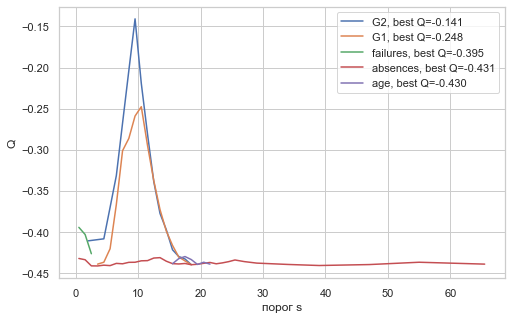

In [86]:
features = ["G2", "G1", "failures", "absences", "age"]
y = df["pass"].values
plt.figure(figsize=(8, 5))
for name in features:
    x = df[name].values
    thresholds, ginis, s_best, q_best = find_best_split(x, y)
    plt.plot(thresholds, ginis, label=f"{name}, best Q={q_best:.3f}")
plt.xlabel("порог s")
plt.ylabel("Q")
plt.legend()
plt.show()

__Наблюдения (Комментарий):__ \
Для каждого столбца порог есть середина соседних разных значений, по лекции 2, часть 3, $s=\frac{v_{(t)}+v_{(t+1)}}{2}, Q(s)=-\frac{|R_L|}{395}H_L-\frac{|R_R|}{395}H_R$
На рисунке G2 поднимается до $-0.141$ около $9.5$, G1 до $-0.248$ около $10.5$. failures имеет три точки и потолок $-0.395$. age и absences лежат около $-0.44$ на всех порогах.

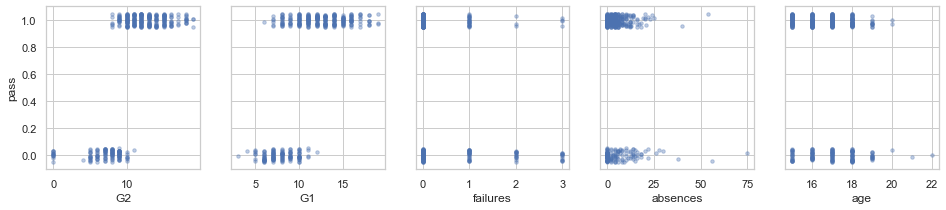

In [87]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for ax, name in zip(axes, features):
    x = df[name].values
    y_jit = y + rng.uniform(-0.05, 0.05, size=len(y))
    ax.scatter(x, y_jit, alpha=0.35, s=12)
    ax.set_xlabel(name)
axes[0].set_ylabel("pass")
plt.show()

__Наблюдения (Комментарий):__ \
Сдвиг $\pm 0.05$ только раздвигает точки на картинке, в find_best_split он не входит. На G2 и G1 нули сидят слева от $10$, единицы справа, поэтому середина около $10$ даёт большой $\Delta Q$. На age и absences нули и единицы лежат на одних и тех же $x$, поэтому $H_L$ и $H_R$ почти равны $H(R)$.

__Ответ:__ Делить выборку в первую очередь нужно по G2. Там $Q=-0.141$ при $s=9.5$, выигрыш $0.301$, и scatter это подтверждает. G1 повторяет ту же картину слабее. failures отделяет только частично. age и absences плоские около $-0.44$, много порогов у пропусков не делает признак информативным.

__Задание 5. (0.25 балла)__

На основании построенных в прошлом задании графиков ответьте на следующие вопросы:

1. По какому признаку нужно производить деление выборки на два поддерева? Почему?

2. Согласуется ли этот результат с тем, что видно на scatter-графиках? Совпадают ли выводы?

3. Как выглядят кривые для тех признаков, по которым классы разделяются почти идеально? Чем отличаются от них кривые для признаков, по которым деление практически невозможно?

**Ответ:**
1. Как я указывал в ответе в задании 4 делить выборку нужно по G2. На графике $Q(s)$ максимум среди пяти кривых равен $-0.141$ при $s=9.5$. Корень до разреза имеет $H(R)=1-p_0^2-p_1^2\approx 0.442, p_1=\frac{265}{395}$. По критерию лекции 2, части 2, $Q(s)=-\frac{|R_L|}{395}H_L-\frac{|R_R|}{395}H_R$ чем ближе к нулю, тем чище дети. Выигрыш G2 равен $0.442-0.141=0.301$. У G1 максимум $-0.248$ при $s=10.5$, выигрыш $0.194$. У failures максимум $-0.395$ при $s=0.5$, выигрыш $0.047$. У age и absences максимум около $-0.430$, выигрыш около $0.011$. CART в узле берёт признак с наибольшим $Q$, здесь это G2.

2. Scatter даёт то же. У G2 и G1 нули сидят слева от $10$, единицы справа, поэтому середина соседей около $10$ отделяет классы. У G2 разделение жёстче, пик выше, чем у G1. У failures ноль провалов смешан, а $1$, $2$ и $3$ уже чаще дают pass равный $0$, отсюда маленький, но не нулевой выигрыш. У age и absences нули и единицы лежат на одних и тех же $x$, кривая плоская. Выводы совпадают.

3. Почти идеальный разрез поднимает кривую одним пиком близко к нулю. Тогда $H_L$ и $H_R$ малы, взвешенная сумма около нуля, и $Q$ около нуля. Так выглядит G2 около $s=9.5$. Если деление почти невозможно, кривая лежит рядом с $-H(R)\approx -0.442$ на всех порогах. Поменять $s$ нечем, $H_L$ и $H_R$ остаются почти как у корня. Так выглядят age и absences. Число порогов тут ни при чём. У пропусков их $33$, у возраста $7$, а высота одна и та же.

__Задание 6. (1.5 балла)__

Разберитесь с уже написанным кодом в классе `DecisionTree` модуля `hw1_code.py`. Исправьте ошибки в методе `_fit_node`, а также реализуйте `_predict_node`.

В данном задании:
* построение дерева осуществляется согласно базовому жадному алгоритму, предложенному на лекции
* выбор лучшего разбиения необходимо производить по критерию Джини
* в качестве критерия останова используется следующий: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку
* ответ в листе $-$ это наиболее часто встречающийся в нём класс
* для категориальных признаков выполняется преобразование, описанное на лекции (можете найти его в конспекте в разделе «Учёт категориальных признаков»)

In [122]:
class DecisionTree:
    def __init__(self, feature_types, max_depth=None, min_samples_split=None, min_samples_leaf=None):
        if np.any(list(map(lambda x: x != "real" and x != "categorical", feature_types))):
            raise ValueError("There is unknown feature type")
        self._tree = {}
        self._feature_types = feature_types
        self._max_depth = max_depth
        self._min_samples_split = min_samples_split
        self._min_samples_leaf = min_samples_leaf

    def _fit_node(self, sub_X, sub_y, node, depth=0):
        if np.all(sub_y == sub_y[0]):
            node["type"] = "terminal"
            node["class"] = sub_y[0]
            return
        feature_best, threshold_best, gini_best, split = None, None, None, None
        for feature in range(sub_X.shape[1]):
            feature_type = self._feature_types[feature]
            if feature_type == "real":
                feature_vector = np.asarray(sub_X[:, feature], dtype=float)
            elif feature_type == "categorical":
                counts = Counter(sub_X[:, feature])
                clicks = Counter(sub_X[sub_y == 1, feature])
                ratio = {key: clicks[key] / counts[key] for key in counts}
                sorted_categories = [k for k, _ in sorted(ratio.items(), key=lambda x: x[1])]
                categories_map = {cat: i for i, cat in enumerate(sorted_categories)}
                feature_vector = np.array([categories_map[v] for v in sub_X[:, feature]], dtype=float)
            else:
                raise ValueError
            _, _, threshold, gini = find_best_split(feature_vector, sub_y)
            if threshold is None:
                continue
            candidate = feature_vector < threshold
            if gini_best is None or gini > gini_best:
                feature_best = feature
                gini_best = gini
                split = candidate
                if feature_type == "real":
                    threshold_best = threshold
                else:
                    threshold_best = [cat for cat, code in categories_map.items() if code < threshold]
        if feature_best is None:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return
        node["type"] = "nonterminal"
        node["feature_split"] = feature_best
        if self._feature_types[feature_best] == "real":
            node["threshold"] = threshold_best
        else:
            node["categories_split"] = threshold_best
        node["left_child"] = {}
        node["right_child"] = {}
        self._fit_node(sub_X[split], sub_y[split], node["left_child"], depth + 1)
        self._fit_node(sub_X[~split], sub_y[~split], node["right_child"], depth + 1)

    def _predict_node(self, x, node):
        if node["type"] == "terminal":
            return node["class"]
        feature = node["feature_split"]
        if self._feature_types[feature] == "real":
            go_left = x[feature] < node["threshold"]
        else:
            go_left = x[feature] in node["categories_split"]
        if go_left:
            return self._predict_node(x, node["left_child"])
        return self._predict_node(x, node["right_child"])

    def fit(self, X, y):
        self._tree = {}
        self._fit_node(np.asarray(X), np.asarray(y), self._tree, depth=0)

    def predict(self, X):
        return np.array([self._predict_node(x, self._tree) for x in np.asarray(X)])

__Проверка:__

In [119]:
# x_test_ = np.array([[1.], [2.], [8.], [9.]])

In [120]:
# y_test_ = np.array([0, 0, 1, 1])

In [121]:
# tree = DecisionTree(feature_types=["real"])
# tree.fit(x_test_, y_test_)
# print(tree.predict(x_test_))
# print(tree._tree)

[0 0 1 1]
{'type': 'nonterminal', 'feature_split': 0, 'threshold': 5.0, 'left_child': {'type': 'terminal', 'class': 0}, 'right_child': {'type': 'terminal', 'class': 1}}


__Наблюдения (Комментарий):__ \
 В шаблоне пять ошибок. Стоп написан != вместо ==. Цикл признаков начинается с 1 и теряет столбец 0. Доля категории считается как $N/N_1$, а надо $N_1/N$. Правому ребёнку отдают sub_y[split], то есть левые метки. Класс листа это пара (класс, сколько), а нужен сам класс. \
Вывод $[0, 0, 1, 1]$ и узел с порогом $5.0$, оба ребёнка листья. Это жадный CART лекции 2, части 3. В корне классы не все равны, $H=1-0.5^2-0.5^2=0.5$ лист не ставим. Цикл идёт по столбцу $j=0$ \
В шаблоне было range(1, ...), этот столбец потерялся бы. find_best_split даёт пороги $1.5$, $5$, $8.5$ и $Q$ равный $-1/3$, $0$, $-1/3$. Максимум $s=5$, $Q=0$. Слева $x<5$, точки $1$ и $2$, класс $0$. Справа $8$ и $9$, класс $1$. \
Рекурсия слева видит $y=(0,0)$, np.all истинно, лист, $c_L=0$. Справа $y=(1,1)$, лист, $c_R=1$. В шаблоне справа было sub_y[split], туда ушли бы нули, и правый лист ответил бы $0$. \
Если разреза нет, класс листа $c=\arg\max_k N_k$ most_common(1) отдаёт пару, поэтому берётся [0][0]. \
_predict_node для $x=2$. Узел не лист, признак $0$, $2<5$, идём влево, там лист $0$. Для $x=8$ условие $8<5$ ложно, идём вправо, лист $1$. \
Категориальный столбец на этих четырёх точках не нужен. Если бы он был, доля категории из лекции $r(a)=\frac{N(y=1,a)}{N(a)}$. \
Категории сортируют по $r(a)$ и нумеруют $0,1,2,\ldots$. Дальше тот же find_best_split. Влево уходят категории с номером меньше порога. В шаблоне делили $N(a)/N(y=1,a)$, это обратная доля, и при нуле единиц было деление на ноль.

__Задание 7. (0.5 балла)__

Протестируйте написанное вами решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Для этого необходимо скачать таблицу agaricus-lepiota.data и применить к каждому столбцу LabelEncoder, чтобы преобразовать строковые имена категорий в натуральные числа.

Первый столбец в рассматриваемой таблице $-$ это целевая переменная ('e' $-$ edible, 'p' $-$ poisonous).

Обучите решающее дерево на $50\%$ случайно выбранных объектов и получите предсказания для оставшейся половины. Вычислите accuracy. Если в предыдущих заданиях вы всё сделали корректно, то у вас должно получиться качество очень близкое единице или даже равное ей.

In [123]:
df = pd.read_csv("agaricus-lepiota.data", header=None)
print(df.shape)
print(df.iloc[0, :4].tolist())

(8124, 23)
['p', 'x', 's', 'n']


__Наблюдения (Комментарий):__ \
Вывод (8124, 23) и ['p', 'x', 's', 'n']. Строк $8124$, столбцов $23$. Все поля строки. Столбец $0$ это метка, p или e. Остальные $22$ это признаки.

In [125]:
from sklearn.preprocessing import LabelEncoder

y_raw = df[0].values
X_raw = df.iloc[:, 1:].values
y = LabelEncoder().fit_transform(y_raw)
X = np.empty_like(X_raw, dtype=int)
for j in range(X_raw.shape[1]):
    X[:, j] = LabelEncoder().fit_transform(X_raw[:, j])
print(X.shape, np.unique(y, return_counts=True))

(8124, 22) (array([0, 1]), array([4208, 3916]))


__Наблюдения (Комментарий):__ \
Вывод (8124, 22) и классы $0$ на $4208$ строках, $1$ на $3916$. LabelEncoder сортирует буквы. e раньше p, поэтому съедобный это $0$, ядовитый это $1$. Для столбца $j$ категория $a$ становится номером $\varphi_j(a)\in\{0,1,\ldots,K_j-1\}$. Дереву всё равно, как называлась буква. Ему нужно, чтобы одинаковые буквы имели один номер.

In [126]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)
print(len(y_train), len(y_test))

4062 4062


__Наблюдения (Комментарий):__ \
Вывод 4062 4062. Половина на train, половина на test, индексы не пересекаются.

In [129]:
from collections import Counter
from sklearn.metrics import accuracy_score

feature_types = ["categorical"] * X.shape[1]
tree = DecisionTree(feature_types=feature_types)
tree.fit(X_train, y_train)
pred = tree.predict(X_test)
print(accuracy_score(y_test, pred), (pred != y_test).sum())

1.0 0


__Наблюдения (Комментарий):__ \
Вывод 1.0 и 0. Все $22$ столбца категориальные, поэтому в каждом узле категория сортируется по доле класса $1$, по лекции 2, $r(a)=\frac{N(y=1,a)}{N(a)}$, потом find_best_split ищет максимум, $Q=-\frac{|R_L|}{N}H_L-\frac{|R_R|}{N}H_R, H=1-p_0^2-p_1^2$. \
Лист ставится, когда $H=0$ или порога нет. Ответ листа это частый класс. На тесте $\mathrm{acc}=\frac1{4062}\sum_{i\in A_{\mathrm{test}}}1\{\hat f(x_i)=y_i\}=1, \hat R_{A_{\mathrm{test}}}=0$. \
Ноль ошибок значит, что каждая тестовая строка попала в лист своего класса. Для грибов так и должно быть. Есть признаки, которые почти сами отделяют ядовитые от съедобных, жадный Джини их берёт, и при $4062$ учебных строках дерево доходит до чистых листьев, которые держатся и на второй половине. Если бы accuracy была заметно ниже $1$, ошибка сидела бы в _fit_node или в категориальном $r(a)$.

__Задание 8. (1 балл)__

Реализуйте в классе `DecisionTree` поддержку параметров `max_depth`, `min_samples_split` и `min_samples_leaf` по аналогии с `sklearn.tree.DecisionTreeClassifier`.

In [130]:
class DecisionTree:
    def __init__(self, feature_types, max_depth=None, min_samples_split=None, min_samples_leaf=None):
        if np.any(list(map(lambda x: x != "real" and x != "categorical", feature_types))):
            raise ValueError("There is unknown feature type")
        self._tree = {}
        self._feature_types = feature_types
        self._max_depth = max_depth
        self._min_samples_split = min_samples_split
        self._min_samples_leaf = min_samples_leaf

    def _fit_node(self, sub_X, sub_y, node, depth=0):
        if np.all(sub_y == sub_y[0]):
            node["type"] = "terminal"
            node["class"] = sub_y[0]
            return
        if self._max_depth is not None and depth >= self._max_depth:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return
        if self._min_samples_split is not None and len(sub_y) < self._min_samples_split:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return

        feature_best, threshold_best, gini_best, split = None, None, None, None
        for feature in range(sub_X.shape[1]):
            feature_type = self._feature_types[feature]
            if feature_type == "real":
                feature_vector = np.asarray(sub_X[:, feature], dtype=float)
            elif feature_type == "categorical":
                counts = Counter(sub_X[:, feature])
                clicks = Counter(sub_X[sub_y == 1, feature])
                ratio = {key: clicks[key] / counts[key] for key in counts}
                sorted_categories = [k for k, _ in sorted(ratio.items(), key=lambda x: x[1])]
                categories_map = {cat: i for i, cat in enumerate(sorted_categories)}
                feature_vector = np.array([categories_map[v] for v in sub_X[:, feature]], dtype=float)
            else:
                raise ValueError

            _, _, threshold, gini = find_best_split(feature_vector, sub_y)
            if threshold is None:
                continue
            candidate = feature_vector < threshold
            if self._min_samples_leaf is not None:
                n_left = int(np.sum(candidate))
                n_right = len(sub_y) - n_left
                if n_left < self._min_samples_leaf or n_right < self._min_samples_leaf:
                    continue
            if gini_best is None or gini > gini_best:
                feature_best = feature
                gini_best = gini
                split = candidate
                if feature_type == "real":
                    threshold_best = threshold
                else:
                    threshold_best = [cat for cat, code in categories_map.items() if code < threshold]

        if feature_best is None:
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0]
            return

        node["type"] = "nonterminal"
        node["feature_split"] = feature_best
        if self._feature_types[feature_best] == "real":
            node["threshold"] = threshold_best
        else:
            node["categories_split"] = threshold_best
        node["left_child"] = {}
        node["right_child"] = {}
        self._fit_node(sub_X[split], sub_y[split], node["left_child"], depth + 1)
        self._fit_node(sub_X[~split], sub_y[~split], node["right_child"], depth + 1)

    def _predict_node(self, x, node):
        if node["type"] == "terminal":
            return node["class"]
        feature = node["feature_split"]
        if self._feature_types[feature] == "real":
            go_left = x[feature] < node["threshold"]
        else:
            go_left = x[feature] in node["categories_split"]
        if go_left:
            return self._predict_node(x, node["left_child"])
        return self._predict_node(x, node["right_child"])

    def fit(self, X, y):
        self._tree = {}
        self._fit_node(np.asarray(X), np.asarray(y), self._tree, depth=0)

    def predict(self, X):
        return np.array([self._predict_node(x, self._tree) for x in np.asarray(X)])

__Наблюдения (Комментарий):__ \
depth приходит из рекурсии. Корень это $0$, ребёнок это depth+1. max_depth запрещает новый вопрос, если уровень уже равен потолку. Ответ листа $c=\arg\max_k N_k$ \
min_samples_split запрещает разрез, если в узле меньше $n_{\mathrm{split}}$ точек. \
min_samples_leaf не делает узел листом сразу. Он выкидывает кандидат, у которого $|R_L|<m$ или $|R_R|<m$. \
Если после этого кандидатов нет, срабатывает старый стоп feature_best is None. \
Если параметр равен None, стоп не работает, дерево как в задании 6.

In [170]:
x_test_ = np.array([[1.], [2.], [8.], [9.]])
y_test_ = np.array([0, 0, 1, 1])
t0 = DecisionTree(["real"], max_depth=0)
t0.fit(x_test_, y_test_)
t1 = DecisionTree(["real"], max_depth=1)
t1.fit(x_test_, y_test_)
t2 = DecisionTree(["real"], min_samples_split=5)
t2.fit(x_test_, y_test_)
t3 = DecisionTree(["real"], min_samples_leaf=3)
t3.fit(x_test_, y_test_)

print(t0._tree["type"])
print(t1._tree["type"], t1._tree.get("threshold"))
print(t2._tree["type"])
print(t3._tree["type"])

terminal
nonterminal 5.0
terminal
terminal


__Наблюдения (Комментарий):__ \
Без стопов единственный разрез $s=5$, слева $2$, справа $2$, $H_L=H_R=0$. \
При max_depth=0 корень уже имеет depth=0, условие $0\ge 0$ истинно, лист. \
Классы $2$ и $2$, most_common берёт $0$. \
При max_depth=1 в корне $0\ge 1$ ложно, разрез $s=5$ ставится. \
Дети приходят с depth=1, там $1\ge 1$, оба листа. \
При min_samples_split=5 в корне $N=4<5$, разрез не ищем. \
При min_samples_leaf=3 порог $s=5$ даёт $|R_L|=|R_R|=2<3$, кандидат выкинут. \
Порог $1.5$ даёт $1$ и $3$, порог $8.5$ даёт $3$ и $1$. Другого разреза с обоими детьми хотя бы по $3$ нет. \
Эти три строки не меняют $Q$. Они только запрещают часть разрезов, которые Джини без них принял бы. Variance падает, потому что лист из одной точки больше не обязателен. Bias может вырасти, если запрет срезал полезный разрез.

__Задание 9. (0.5 балла)__

Проверьте, спасают эти параметры вас от переобучения.

Для этого **решите при помощи собственной имплементации `DecisionTree`  задачу классификации цвета вина** (color) по его химическим характеристикам на датасете [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality).

Как обычно, случайно разбейте свой датасет на тест-трейн (в отношении 7:3), и далее сравните на них поведение двух деревьев:
- Для первого дерева не используйте параметры из задания 8
- Для второго дерева выберите разумные значения этих параметров (в этом конкретном случае мы рекомендуем `max_depth=8, min_samples_leaf=5, min_samples_split=17`), и постройте дерево с их использованием.
  - Подбирать оптимальные параметры здесь не требуется

Выведите метрики качества классификации. **Что вы наблюдаете, и почему так произошло?**


В качестве sanity check сравните качество работы и структуру вашего второго дерева с результатом стандартной имплементации из `sklearn`. Не забудьте подать ему на вход те же параметры.

**Обратите внимание, что в оригинале таргетом является качество вина; мы же с вами предсказываем его цвет.** В каком-то смысле, это модель-сомелье.


*Андер-сэмплирование данных далее сделано специально, чтобы продемонстрировать должный эффект. Убирать его запрещается.*

In [133]:
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")
red["color"] = "red"
white["color"] = "white"
df_all = pd.concat([red, white], ignore_index=True)
print(df_all.shape, df_all["color"].value_counts().to_dict())

(6497, 13) {'white': 4898, 'red': 1599}


__Наблюдения (Комментарий):__ \
Вывод (6497, 13), белых $4898$, красных $1599$. Тринадцатый столбец это цвет, его нет в исходных файлах. quality остаётся признаком, не меткой.

In [135]:
np.random.seed(0)
df = df_all.sample(frac=0.1)
print(len(df), df["color"].value_counts().to_dict())
X = df.drop(columns=["color"])
y = LabelEncoder().fit_transform(df["color"])
X_train, X_test, y_train, y_test = train_test_split(
    X.values, y, test_size=0.3, random_state=0
)
print(len(y_train), len(y_test), np.bincount(y_test))

650 {'white': 494, 'red': 156}
455 195 [ 42 153]


__Наблюдения (Комментарий):__ \
Вывод $650$, белых $494$, красных $156$, затем $455$ и $195$, на тесте $[42, 153]$. Отношение $455:195=7:3$. red по алфавиту раньше white, поэтому $0$ это красное, $1$ это белое. Признаков $12$, все вещественные, feature_types=["real"]*12. Десятую часть убирать нельзя. Без неё переобучение на цвете почти не видно.

In [137]:
feature_types = ["real"] * X.shape[1]
free = DecisionTree(feature_types)
free.fit(X_train, y_train)
print("free", accuracy_score(y_train, free.predict(X_train)), accuracy_score(y_test, free.predict(X_test)))

reg = DecisionTree(feature_types, max_depth=8, min_samples_leaf=5, min_samples_split=17)
reg.fit(X_train, y_train)
print("reg", accuracy_score(y_train, reg.predict(X_train)), accuracy_score(y_test, reg.predict(X_test)))
print(classification_report(y_test, reg.predict(X_test)))

sk = DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, min_samples_split=17, random_state=0)
sk.fit(X_train, y_train)
print("sk", accuracy_score(y_train, sk.predict(X_train)), accuracy_score(y_test, sk.predict(X_test)))
print(sk.get_depth(), sk.get_n_leaves())

free 1.0 0.9846153846153847
reg 0.9846153846153847 0.9846153846153847
              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.99      0.99       153

    accuracy                           0.98       195
   macro avg       0.97      0.98      0.98       195
weighted avg       0.98      0.98      0.98       195

sk 0.9846153846153847 0.9846153846153847
4 7


__Наблюдения (Комментарий):__ \
Без стопов train $1.0$, test $0.984615$. Со стопами оба $0.984615$. Sklearn тоже $0.984615$, глубина $4$, листьев $7$.
$$\hat R_A^{\mathrm{free}}=0,\qquad \hat R_{A_{\mathrm{test}}}=\frac{3}{195}\approx 0.015,\qquad \mathrm{gap}=0.015$$
$$\hat R_A^{\mathrm{reg}}=\frac{7}{455},\qquad \hat R_{A_{\mathrm{test}}}=\frac{3}{195},\qquad \mathrm{gap}=0$$
**Проверка долей.** \
$192/195=448/455=0.984615$. \
Train упал с $455/455$ до $448/455$, test не изменился. \
Стопы убрали листья, которые держали учебный шум. \
Потолок $8$ не сработал, дерево и так остановилось на $4$. \
Сработал min_samples_leaf=5. \
Разрез, после которого в ребёнке меньше $5$ точек, выкинут. \
Sklearn на тех же стопах совпал и по риску, и по структуре, глубина $4$, листьев $7$. \
Стопы от переобучения спасают в том смысле, что gap с $0.015$ стал $0$. Сам test не вырос. \
Задача цвета слишком простая, чтобы ограничение глубины что то добирало. Андерсэмплинг как раз для того, чтобы без стопов train успел дойти до $1$.

## Bias-variance decomposition (3 балла)

В этой части задания воспользуемся возможностями бутстрапа для оценки смещения и разброса алгоритмов машинного обучения.

В этом разделе мы будем работать с датасетом `California housing` из `sklearn.datasets.fetch_california_housing`. Это задача регрессии: по признакам района (доход, возраст домов и т.п.) нужно предсказать MedHouseVal - медианная стоимость жилья.

In [ ]:
california = fetch_california_housing()
X = california["data"]
y = california["target"]

X.shape, y.shape

Во всех заданиях этого раздела (задания 10-11) используйте одни и те же данные `X, y` и три стандартные модели из sklearn:

* `LinearRegression`
* `DecisionTreeRegressor`
* `RandomForestRegressor`

Все три модели имеют единый интерфейс, что позволит передавать их в общие функции.


### Вычисление bias и variance (1.5 балл)

На лекции была выведена следующая формула, показывающая, как можно представить ошибку алгоритма регрессии в виде суммы трех компонент:
$$
L(\mu) =
    \mathbb{E}_{x, y}\bigl[\mathbb{E}_{X}\bigl[ (y - \mu(X)(x))^2 \bigr]\bigr] =
$$

$$
    \underbrace{\mathbb{E}_{x, y}\bigl[(y - \mathbb{E}[y|x] )^2\bigr]}_{\text{шум}} + \underbrace{\mathbb{E}_{x}\bigl[(\mathbb{E}_{X}[\mu(X)(x)] - \mathbb{E}[y|x] )^2\bigr]}_{\text{смещение}} +
    \underbrace{\mathbb{E}_{x}\bigl[\mathbb{E}_{X}\bigl[(\mu(X)(x) - \mathbb{E}_{X}[\mu(X)(x)] )^2\bigr]\bigr]}_{\text{разброс}},
$$
* $\mu(X)$ — алгоритм, обученный по выборке $X = \{(x_1, y_1), \dots (x_\ell, y_\ell)\}$;
* $\mu(X)(x)$ — ответ алгоритма, обученного по выборке $X$, на объекте $x$;
* $\mathbb{E}_{X}$ — мат. ожидание по всем возможным выборкам;
* $\mathbb{E}_{X}[\mu(X)(x)]$ — "средний" ответ алгоритма, обученного по всем возможным выборкам $X$, на объекте $x$.
    
С помощью этой формулы мы можем анализировать свойства алгоритма обучения модели $\mu$, если зададим вероятностную модель порождения пар $p(x, y)$.

В реальных задачах мы, конечно же, не знаем распределение на парах объект - правильный ответ. Однако у нас есть набор семплов из этого распределения (обучающую выборка), и мы можем использовать его, чтобы оценивать математические ожидания. Для оценки мат. ожиданий по выборкам мы будем пользоваться бутстрэпом - методом генерации "новых" выборок из одной с помощью выбора объектов с возвращением. Разберем несколько шагов на пути к оценке смещения и разброса.

#### **Приближенное вычисление интегралов**

Для большинства моделей данных и алгоритмов обучения аналитически рассчитать математические ожидания в формулах не удастся. Однако мат. ожидания можно оценивать приближенно. Чтобы оценить математическое ожидание $\mathbb{E}_{\bar z} f(\bar z)$ функции от многомерной случайной величины $\bar z = (z_1, \dots, z_d)$, $\bar z \sim p(\bar z)$, можно сгенерировать выборку из распределения $p(\bar z)$ и усреднить значение функции на элементах этой выборки:
$$\mathbb{E}_{\bar z} f(z) = \int f(\bar z) p(\bar z) d \bar z \approx \frac 1 m \sum_{i=1}^m f(\bar z_i), \, \bar z_i \sim p(\bar z), i = 1, \dots, m.$$

Например, оценим $\mathbb{E}_z z^2,$ $z \sim \mathcal{N}(\mu=5, \sigma=3)$ (из теории вероятностей мы знаем, что
$\mathbb{E}_z z^2 = \sigma^2 + \mu^2 = 34$):

In [ ]:
z = np.random.normal(loc=5, scale=3, size=1000)
(z**2).mean()

33.932175246772296

#### **Оценивание $\mathbb{E}_{x, y}$**

Оценить мат. ожидания по $x$ и по $x, y$, встречающиеся во всех трех компонентах разложения, несложно, потому что у нас есть выборка объектов из распределения данных $p(x, y)$:
$$ \mathbb{E}_{x} f(x) \approx \frac 1 N \sum_{i=1}^N f(x_i), \quad
\mathbb{E}_{x, y} f(x, y) \approx \frac 1 N \sum_{i=1}^N f(x_i, y_i),$$
где $N$ - число объектов в выборке, $\{(x_i, y_i)\}_{i=1}^N$ - сама выборка.

#### **Оценивание $\mathbb{E}_X$ с помощью бутстрапа**

Чтобы оценить мат. ожидание по $X$, нам понадобится выборка из выборок:
$$\mathbb{E}_X f(X) \approx \frac 1 s \sum_{j=1}^s f(X_j),$$
где $X_j$ - $j$-я выборка. Чтобы их получить, мы можем воспользоваться бутстрапом - методом генерации выборок на основе выбора объектов с возвращением. Чтобы составить одну выборку, будем $N$ раз выбирать индекс объекта $i \sim \text{Uniform}(1 \dots N)$ и добавлять $i$-ю пару (объект, целевая переменная) в выборку. В результате в каждой выборке могут появиться повторяющиеся объекты, а какие-то объекты могут вовсе не войти в некоторые выборки.

**Почему именно выбор с возвращением?**

В классическом бутстрапе мы считаем, что единственное, что у нас есть про распределение данных $p(x, y)$, - это эмпирическое распределение на нашей выборке: каждый объект имеет вероятность $1/N$. Тогда "новая" обучающая выборка размера $N$ моделируется как $N$ независимых выборов *с возвращением* из этого эмпирического распределения.

Отсюда появляются:
* повторы объектов в бутстрап-выборке,
* и, наоборот, out-of-bag объекты, которые в конкретную бутстрап-выборку не попали.

Повторы не являются ошибкой или "зашумлением" эксперимента - они как раз и отражают то, насколько алгоритм чувствителен к конкретным объектам (в том числе к выбросам). Если бы мы каждый раз просто брали подвыборки без возвращения, мы бы изучали уже немного другую процедуру (скорее subsampling / k-fold CV), а не классический бутстрап.

#### **Итоговый алгоритм оценки смещения и разброса алгоритма $a$**
1. Сгенерировать $s$ выборок $X_j$ методом бутстрапа.
1. На каждой выборке $X_j$ обучить алгоритм $a_j$.
1. Для каждой выборки $X_j$ определить множество объектов $T_j$, не вошедших в нее (out-of-bag). Вычислить предсказания алгоритма $a_j$ на объектах $T_j$.

Поскольку у нас есть только один ответ для каждого объекта, мы будем считать шум равным 0, а $\mathbb{E}[y|x]$ равным имеющемуся правильному ответу для объекта $x$.

Итоговые оценки:
* Смещение: для одного объекта - квадрат разности среднего предсказания и правильного ответа. Среднее предсказание берется только по тем алгоритмам $a_j$, для которых этот объект входил в out-of-bag выборку $T_j$. Для получения общего смещения выполнить усреденение смещений по объектам.
* Разброс: для одного объекта - выборочная дисперсия предсказаний алгоритмов $a_j$, для которых этот объект входил в out-of-bag выборку $T_j$. Для получения общего разброса выполнить усреденение разбросов по объектам.
* Ошибка $L$: усреднить квадраты разностей предсказания и правильного ответа по всем выполненным предсказаниям для всех объектов.

В результате должно получиться, что ошибка приблизительно равна сумме смещения и разброса!

__Задание 10.1 (1 балл)__

Реализуйте описанный алгоритм. Обратите внимание, что если объект не вошел ни в одну из out-of-bag выборок, учитывать его в вычислении итоговых величин не нужно. Как обычно, разрешается использовать только один цикл - по выборкам (от 0 до num_runs-1).

In [171]:
def compute_biase_variance(model, X, y, num_runs=1000):
    n = X.shape[0]
    pred_sum = np.zeros(n)
    pred_sq_sum = np.zeros(n)
    err_sum = np.zeros(n)
    counts = np.zeros(n)
    for _ in range(num_runs):
        idx = np.random.choice(n, size=n, replace=True)
        oob = np.ones(n, dtype=bool)
        oob[idx] = False
        if not np.any(oob):
            continue
        model.fit(X[idx], y[idx])
        pred = model.predict(X[oob])
        pred_sum[oob] += pred
        pred_sq_sum[oob] += pred ** 2
        err_sum[oob] += (pred - y[oob]) ** 2
        counts[oob] += 1
    ok = counts > 0
    mean_pred = pred_sum[ok] / counts[ok]
    mean_sq = pred_sq_sum[ok] / counts[ok]
    bias = np.mean((mean_pred - y[ok]) ** 2)
    variance = np.mean(mean_sq - mean_pred ** 2)
    error = err_sum[ok].sum() / counts[ok].sum()
    return bias, variance, error

__Наблюдения (Комментарий):__ \
В лекции 1, части 2, раскладывается ошибка регрессии на шум, bias и variance. В задании на объект есть один ответ, поэтому шум считают нулём и $\mathbb E[y|x]$ заменяют на $y_i$. Тогда $L\approx \mathrm{bias}+\mathrm{variance}$ np.random.choice(..., replace=True) это бутстрап. \
Индекс можно вытянуть несколько раз, какой то индекс не вытянуть совсем. \
Доля невытянутых около $(1-1/n)^n\to e^{-1}\approx 0.368$. Это множество $T_j$. \
На объекте $i$, который был out of bag $n_i$ раз, $\bar a_i=\frac1{n_i}\sum_{j:i\in T_j}a_j(x_i)$$
$$\mathrm{bias}_i=(\bar a_i-y_i)^2, \mathrm{var}_i=\frac1{n_i}\sum_j a_j(x_i)^2-\bar a_i^2$ \
Общие числа это среднее по объектам с $n_i>0$. \
Error усредняет квадрат не по объектам, а по всем парам $(j,i)$ с $i\in T_j$. Поэтому error делит на сумму counts, а не на число объектов.

In [172]:
california = fetch_california_housing()
X = california["data"]
y = california["target"]
print(X.shape, y.shape)
np.random.seed(0)
X_small, y_small = X[:400], y[:400]
bias, var, err = compute_biase_variance(LinearRegression(), X_small, y_small, num_runs=100)
print("LR", bias, var, err, bias + var, abs(err - bias - var))
bias, var, err = compute_biase_variance(DecisionTreeRegressor(max_depth=3), X_small, y_small, num_runs=100)
print("tree", bias, var, err, bias + var, abs(err - bias - var))

(20640, 8) (20640,)
LR 0.2416889905509103 0.010802020133434618 0.24983089662576938 0.25249101068434493 0.0026601140585755505
tree 0.22500411903611797 0.08463203023414828 0.29703618535155735 0.3096361492702663 0.012599963918708906


__Наблюдения (Комментарий):__ \
Вывод формы (20640, 8). На $400$ строках и $100$ бутстрапах прямая дала bias $0.242$, variance $0.011$, error $0.250$, сумма $0.252$, модуль разности $0.0027$. Дерево глубины $3$ дало bias $0.225$, variance $0.085$, error $0.297$, сумма $0.310$, модуль разности $0.013$. Равенство не точное. Дисперсия в variance это среднее по объектам, а error это среднее по предсказаниям. На полном $s=1000$ эта разность сжимается. Если variance отрицательная, перепутаны mean_sq и mean_pred**2. Если error далеко от суммы уже на $1000$ прогонах, в среднее попали объекты с counts=0.

__Задание 10.2 (0.25 баллов)__

Оцените смещение, разброс и ошибку для трех алгоритмов с гиперпараметрами по умолчанию: линейная регрессия, решающее дерево, случайный лес.

Проанализируйте полученный результат. Согласуются ли полученные результаты с теми, что обсуждались на занятиях?

In [142]:
models = {
    "LinearRegression": LinearRegression(),
    "DecisionTree": DecisionTreeRegressor(),
    "RandomForest": RandomForestRegressor(),
}

for name, model in models.items():
    bias, var, err = compute_biase_variance(model, X, y, num_runs=100)
    print(name)
    print("bias", bias)
    print("variance", var)
    print("error", err)
    print("bias+var", bias + var)

LinearRegression
bias 0.546301156334949
variance 0.13823822548842266
error 0.682834728115406
bias+var 0.6845393818233717
DecisionTree
bias 0.2490365082326078
variance 0.29342196167186185
error 0.5428373969829893
bias+var 0.5424584699044697
RandomForest
bias 0.24716032649726302
variance 0.018433594214065353
error 0.2653009437901135
bias+var 0.26559392071132837


**Ответ:** \
Шум в задании равен нулю, вместо $\mathbb E[y|x]$ стоит сам $y_i$. Проверка по лекции 1, части 2, $L\approx\mathrm{bias}+\mathrm{variance}$ \
У прямой $0.546+0.138=0.685$ против error $0.683$. У дерева $0.249+0.293=0.542$ против $0.543$. У леса $0.247+0.018=0.266$ против $0.265$. Равенство держится, gap около $0.002$.
Линейная регрессия это $\mu(x)=x^\top\beta$. Bias $0.546$ самый большой. Прямая не повторяет цену района. Variance $0.138$ меньше, чем у дерева. Один и тот же $\beta$ слабо прыгает от бутстрапа к бутстрапу.
Дерево по умолчанию растёт до чистого листа. Bias падает до $0.249$, это $0.546/0.249\approx 2.2$ раза меньше, чем у прямой. Variance вырастает до $0.293$. Лист из одной точки на out of bag уже другой. Это лекция 2, часть 4. Низкий bias, высокий variance.
Лес это среднее деревьев на бутстрапе и случайном подмножестве признаков, по лекции 3, части 1 и 2.
$$\mathrm{Var}(\bar T_B)=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2$$
Bias $0.247$ почти как у одного дерева, $0.249$. Усреднение смещение не убирает. Variance падает с $0.293$ до $0.018$, примерно в $0.293/0.018\approx 16$ раз. Ошибка падает с $0.543$ до $0.265$ почти целиком за счёт разброса.
С лекцией согласуется. Прямая смещена и устойчива. Дерево мало смещено и нестабильно. Лес оставляет смещение дерева и срезает разброс.

__Задание 10.3 (0.25 баллов)__
Постройте бэггинг над всеми тремя моделями (линейная регрессия, решающее дерево, случайный лес). Вспомните обсуждение с лекции о том, во сколько раз в теории бэггинг уменьшает разброс базового алгоритма. Выполняется ли это в ваших экспериментах? Если нет, поясните, почему.

In [145]:
base = {
    "bagging + LR": LinearRegression(),
    "bagging + DT": DecisionTreeRegressor(),
    "bagging + RF": RandomForestRegressor(n_estimators=10),
}

for name, m in base.items():
    bag = BaggingRegressor(m, n_estimators=10)
    bias, var, err = compute_biase_variance(bag, X, y, num_runs=100)
    print(name)
    print("bias", bias)
    print("variance", var)
    print("error", err)
    print("bias+var", bias + var)

bagging + LR
bias 0.6590576706171785
variance 0.2932936623799288
error 0.96495269917073
bias+var 0.9523513329971073
bagging + DT
bias 0.24755712992107015
variance 0.04524138844887349
error 0.29325106921707167
bias+var 0.29279851836994364
bagging + RF
bias 0.25580891596625693
variance 0.012709675585146818
error 0.26862382246112826
bias+var 0.26851859155140373


**Ответ:** 
Вывод. Прямая bias $0.659$, variance $0.293$, error $0.965$. Дерево bias $0.248$, variance $0.045$, error $0.293$. Лес bias $0.256$, variance $0.013$, error $0.269$. База из 10.2. Прямая variance $0.138$, дерево $0.293$, лес $0.018$.
Если ответы независимы, по лекции 3, часть 1, даёт $\mathrm{Var}\left(\frac1B\sum_{b=1}^B a_b\right)=\frac{\sigma^2}{B}$ \
При $B=10$ разброс должен упасть в $10$ раз. На бутстрапе они не независимы, $\mathrm{Var}(\bar a_B)=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2$ \
При $\rho=1$ усреднение не режет ничего. При $\rho=0$ режет в $B$ раз.
Дерево. Было $0.293$, стало $0.045$.
$$\frac{0.293}{0.045}\approx 6.5$$
Не $10$. Подстановка в формулу с $\rho$:
$$\frac{0.045}{0.293}\approx 0.154,\qquad \rho+\frac{1-\rho}{10}=0.154,\qquad \rho\approx 0.060$$
Падение есть, деревья на пересекающихся бутстрапах чуть похожи. Bias остался $0.248$ против $0.249$. Бэггинг смещение не убрал, ошибка упала с $0.543$ до $0.293$ за счёт разброса.
Прямая. Было $0.138$, стало $0.293$. В $10$ раз не упало, выросло. Bias тоже уехал, с $0.546$ до $0.659$, error с $0.683$ до $0.965$. Формула $\sigma^2/B$ здесь не выполняется. У линейной регрессии $\rho$ близко к $1$, на разных бутстрапах $\beta$ почти один и тот же, усреднение нечего срезать. Рост оценки ещё и от того, что внешний бутстрап сидит поверх внутреннего. BaggingRegressor уже выбирает с возвращением, compute_biase_variance выбирает ещё раз. Для устойчивой прямой это шумит оценку, а не уменьшает разброс.
Лес. Было $0.018$, стало $0.013$.
$$\frac{0.018}{0.013}\approx 1.5$$
Не $10$. Внутри леса усреднение уже сделано, внешние $10$ копий срезают остаток. Bias $0.256$ против $0.247$, почти тот же.
Множитель $B$ в эксперименте не выполняется. Близко к нему только дерево, и то в $6.5$ раза, $\rho\approx 0.06$. Прямая почти не декоррелируется. Лес уже сам бэггинг, второй слой даёт около полутора раз.

### Визуализация предсказаний базовых алгоритмов бэггинга (1.5 балл)

Мы уже неоднократно обращались к известной иллюстрации, визуализирующей алгоритмы с разным смещением и разбросом.

![](https://nvsyashwanth.github.io/machinelearningmaster/assets/images/bias_variance.jpg)

В этом задании вам предстоит построить похожее изображение для трёх алгоритмов. Вы будете решать задачу одномерной регрессии, поэтому ваши итоговые мишени будут одномерными.

__Задание 11.1 (1 балл)__

Реализуйте функцию `plot_predictions`, которая должна выполнять следующие шаги:

1. Выбор подмножества данных. Случайным образом выберите num_test_objects пар "объект-целевая переменная" из исходных данных X, y. Выбранные объекты образуют тестовую выборку X_test, y_test, остальные - обучающую выборку X_train, y_train.

2. Метод бутстрапа. Сгенерируйте методом бутстрапа num_runs новых выборок из X_train, y_train. На каждой такой выборке обучите алгоритм и сделайте предсказания для объектов X_test.

3. Построение графика. Нарисуйте scatter-график, где по оси абсцисс - номера тестовых объектов от 0 до num_test_objects - 1 (а не сами значения признаков); по оси ординат - предсказания моделей на этих объектах. В итоге должно получиться num_test_objects вертикальных столбиков из точек: для каждого тестового объекта его num_runs предсказаний.

   Для каждого тестового объекта:
   * отметьте все предсказания для него одним цветом (чтобы был виден столбик);
   * истинный ответ y_test для этого объекта отметьте чёрной точкой.

Не забудьте подписать оси, а также добавить заголовок графика.

> *Примечание.* Раскраска предсказаний по тестовым объектам нужна только для удобства: так легче визуально отличать столбики друг от друга. Можно также сделать все предсказания одного цвета, а истинные значения - чёрными.
>
> Если хотите более явно увидеть bias–variance, можно дополнительно построить второй график, где по оси X - номера тестовых объектов, а по оси Y - разница `mean_pred(x_i) − y_i` (оценка bias), и, например, показать разброс предсказаний в виде вертикальных отрезков или доверительных интервалов.
>
> При больших значениях num_runs вместо (или вместе с) отдельных точек допустимо использовать boxplot/violinplot.


In [147]:
def plot_predictions(model, X, y, num_runs=100, num_test_objects=10, title=""):
    n = len(y)
    test_idx = np.random.choice(n, size=num_test_objects, replace=False)
    train_idx = np.setdiff1d(np.arange(n), test_idx)
    X_train, y_train = X[train_idx], y[train_idx]
    X_test, y_test = X[test_idx], y[test_idx]
    preds = np.zeros((num_runs, num_test_objects))
    for i in range(num_runs):
        boot = np.random.choice(len(y_train), size=len(y_train), replace=True)
        model.fit(X_train[boot], y_train[boot])
        preds[i] = model.predict(X_test)
    plt.figure(figsize=(8, 4))
    xs = np.arange(num_test_objects)
    for j in xs:
        plt.scatter(np.full(num_runs, j), preds[:, j], alpha=0.25, s=18)
        plt.scatter(j, y_test[j], color="black", s=40, zorder=3)
    plt.xticks(xs)
    plt.xlabel("номер тестового объекта")
    plt.ylabel("предсказание")
    plt.title(title)
    plt.show()

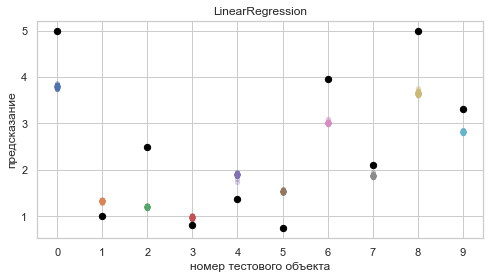

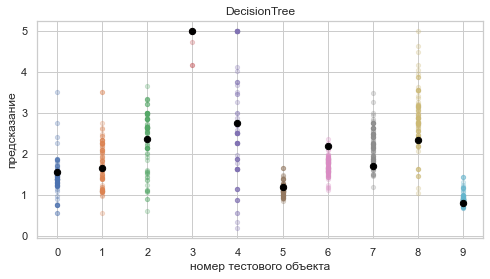

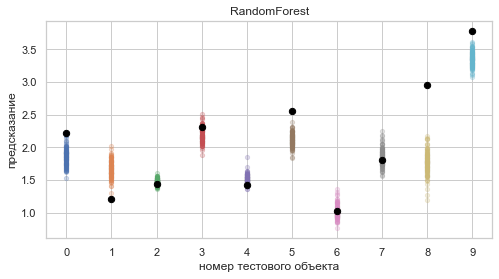

In [148]:
plot_predictions(LinearRegression(), X, y, title="LinearRegression")
plot_predictions(DecisionTreeRegressor(), X, y, title="DecisionTree")
plot_predictions(RandomForestRegressor(n_estimators=20), X, y, title="RandomForest")

test_idx выбирает $m=10$ пар без возвращения. Это не бутстрап. Бутстрап начинается в цикле и только по train. Иначе объект попал бы и в учёбу, и в мишень. Для объекта $j$ столбик это $\{\mu_b(x_j)\}_{b=1}^{B}$. Среднее столбика $\bar a_j=\frac1B\sum_{b=1}^{B}\mu_b(x_j)$ \
Смещение на картинке это $\bar a_j-y_j$, чёрная точка это $y_j$. Разброс это высота столбика, $\mathrm{Var}_j=\frac1B\sum_{b=1}^{B}\mu_b(x_j)^2-\bar a_j^2$ \
Цвет столбика ничего не считает, он только отделяет объект $j$ от $j+1$.
Оси $y$ разные. У леса потолок $3.5$, у прямой и дерева $5$, поэтому высоту столбиков между панелями напрямую не сравнивают. Внутри панели сравнивать можно.
У прямой столбик короткий. На объекте $0$ все $\mu_b$ сидят около $3.8$, чёрная точка $y_0=5$.
$$\bar a_0-y_0\approx 3.8-5=-1.2,\qquad (\bar a_0-y_0)^2\approx 1.44$$
На объекте $8$ столбик около $3.7$, чёрная на $5$. На объекте $6$ столбик около $3$, чёрная на $4$. Разброс маленький, смещение большое. Это печать 10.2, bias $0.546$, variance $0.138$. Прямая $x^\top\beta$ от бутстрапа почти не прыгает и до цены не дотягивается.
У дерева столбик высокий. Объекты $3$ и $4$ растянуты примерно от $1$ до $5$, чёрная внутри столбика. Объект $8$ тоже от $1.5$ до $5$. Чёрная внутри значит $\bar a_j$ ближе к $y_j$, чем у прямой. Bias меньше, variance больше. Это $0.249$ и $0.293$. Лист из одной точки на новом бутстрапе другой, отсюда вертикальный разброс.
У леса столбик сжат. Центр рядом с чёрной не везде. Объект $9$, столбик около $3.4$, чёрная на $3.7$. Объект $1$, столбик около $1.7$, чёрная на $1.2$. Смещение как у дерева, разброс срезан усреднением. Это $0.247$ и $0.018$.
Картинка согласуется с 10.2. Прямая смещена и устойчива. Дерево мало смещено и нестабильно. Лес оставляет смещение дерева и укорачивает столбик. Чтобы масштаб был один и мишени были общие, в 11.2 три панели нужно рисовать с одним test_idx и sharey=True.

__Задание 11.2 (0.5 балла)__

Нарисуйте графики для линейной регрессии, решающего дерева и случайного леса в строчку с одинаковой осью ординат. Это поможет корректно проанализировать масштаб разброса у каждого из этих алгоритмов.

Для каждого графика прокомментируйте, как он характеризует смещение и разброс соответствующего алгоритма.

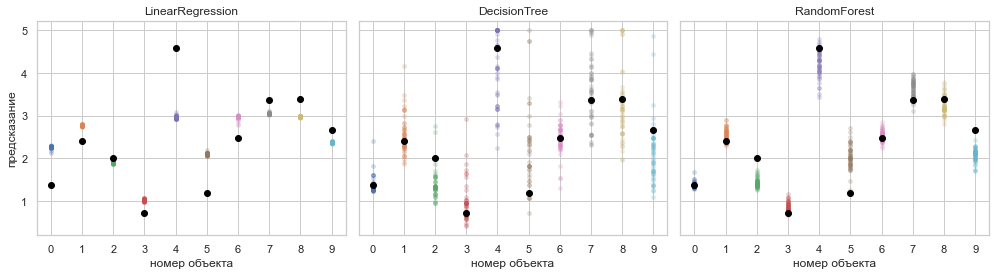

In [149]:
def plot_predictions_row(models, titles, X, y, num_runs=50, num_test_objects=10):
    n = len(y)
    test_idx = np.random.choice(n, size=num_test_objects, replace=False)
    train_idx = np.setdiff1d(np.arange(n), test_idx)
    X_train, y_train = X[train_idx], y[train_idx]
    X_test, y_test = X[test_idx], y[test_idx]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
    xs = np.arange(num_test_objects)
    for ax, model, title in zip(axes, models, titles):
        preds = np.zeros((num_runs, num_test_objects))
        for i in range(num_runs):
            boot = np.random.choice(len(y_train), size=len(y_train), replace=True)
            model.fit(X_train[boot], y_train[boot])
            preds[i] = model.predict(X_test)
        for j in xs:
            ax.scatter(np.full(num_runs, j), preds[:, j], alpha=0.2, s=14)
            ax.scatter(j, y_test[j], color="black", s=36, zorder=3)
        ax.set_title(title)
        ax.set_xlabel("номер объекта")
        ax.set_xticks(xs)
    axes[0].set_ylabel("предсказание")
    plt.tight_layout()
    plt.show()

np.random.seed(0)
plot_predictions_row(
    [LinearRegression(), DecisionTreeRegressor(), RandomForestRegressor(n_estimators=20)],
    ["LinearRegression", "DecisionTree", "RandomForest"],
    X, y,
)

**Ответ:** \
test_idx один на все три панели. Чёрная точка объекта $j$ одна и та же. Бутстрап свой у каждой модели, поэтому столбики разные. sharey не даёт лесу сжать ось и выглядеть таким же высоким, как дерево. В 11.1 мишени были разные, здесь их можно сравнивать.
Общая ось от $1$ до $5$. Высоту столбика уже можно читать как масштаб разброса.
$$\bar a_j=\frac1B\sum_{b=1}^{B}\mu_b(x_j),\qquad \mathrm{Var}_j=\frac1B\sum_{b=1}^{B}\mu_b(x_j)^2-\bar a_j^2$$
Смещение на объекте это $\bar a_j-y_j$.
У прямой столбик почти точка. На объекте $4$ все $\mu_b$ сидят около $3$, чёрная на $4.6$.
$$\bar a_4-y_4\approx 3-4.6=-1.6$$
На объекте $0$ облако около $2.2$, чёрная около $1.4$. На объекте $5$ облако около $2.1$, чёрная около $1.2$. Разброс маленький, смещение большое. Это печать 10.2, bias $0.546$, variance $0.138$. $\beta$ от бутстрапа почти не прыгает и до цены не дотягивается.
У дерева столбик самый высокий на этой оси. Объект $4$ растянут примерно от $1.5$ до $5$, чёрная на $5$, внутри столбика. Объект $8$ от $2$ до $5$, чёрная около $3.2$, тоже внутри. Лист из одной точки на новом бутстрапе другой. Bias меньше, чем у прямой, variance больше. В 10.2 это $0.249$ и $0.293$.
У леса на той же оси столбик короче дерева и центр рядом с деревом. Объект $4$ сжат около $4.3$ и $4.7$, чёрная на $4.6$. Объект $7$ сжат около $3.3$ и $4$, чёрная около $3.4$. Усреднение $\bar a_j=\frac1B\sum_b\mu_b(x_j)$ срезает разброс и не двигает смещение. В 10.2 bias $0.247$ почти как у дерева, variance $0.018$ против $0.293$.
Картинка согласуется с 10.2. Прямая смещена и устойчива. Дерево мало смещено и нестабильно. Лес оставляет смещение дерева и укорачивает столбик.

**Источники:** \
**Промты к LLM:** 
1. Почему ноль ошибок на тех объектах, по которым правило строилось, ещё не говорит, что правило поймало форму, а не отдельные точки?
2. Если лист можно сделать из одной точки, какая часть ошибки на этих точках обязана обнулиться, а какая нет?
3. Один вопрос режет плоскость на две части. Двух колец он не отделяет. Какой следующий вопрос имеет смысл задавать и почему одного уже мало?
4. На картинке разделяющей поверхности есть узкий прямоугольник, в котором лежит одна точка. Что с ним произойдёт, если эту точку убрать из построения?
5. Порог стоит посередине двух соседних значений. Что сломается, если поставить его ровно в одно из значений?
6. Критерий качества разреза отрицательный и его максимизируют. Какая величина при этом на самом деле уменьшается?
7. Если два порога дают одно и то же качество, какой из них брать и почему выбор не произвольный?
8. Доля категории посчитана как размер категории, делённый на число объектов нужного класса. При каком наборе меток это выражение нельзя посчитать?
9. Правому поддереву отдали те же метки, что и левому. На каком объекте предсказание разойдётся с меткой, даже если разрез был верный?
10. Потолок глубины равен нулю. Разрез с идеальным критерием уже найден. Почему его всё равно нельзя ставить?
11. Ограничение на размер листа выкинуло единственный кандидат. Чем этот узел отличается от узла, в котором все метки и так одинаковые?
12. На одном признаке кривая критерия поднимается к нулю, на другом лежит рядом с нечистотой корня. Какой признак брать первым и что должно быть видно на расположении меток?
13. Почему предыдущая оценка по тому же предмету опасна как признак, если метка сделана из итоговой оценки?
14. Объект не попал в порцию, собранную с возвращением. Почему его ответ можно использовать для проверки именно этой порции и почему нельзя усреднять его с объектами, которые не попали ни в одну такую порцию?
15. Смещение объекта считается по среднему ответу, ошибка считается по каждому ответу отдельно. Почему их сумма не обязана совпасть с ошибкой, пока порций мало?
16. Прямая почти не меняется от порции к порции, дерево меняется сильно. Во сколько раз усреднение имеет право уменьшить разброс в первом случае и во втором?
17. Поверх уже усреднённого правила поставили ещё одно усреднение. Какая величина мешает разбросу упасть ещё в число копий?
18. На рисунке столбик короткий, а чёрная точка далеко от него. Это смещение или разброс, и почему соседний высокий столбик с чёрной точкой внутри говорит об обратном?
19. Три панели нарисованы отдельными вызовами. Почему высоту столбика объекта 0 нельзя сравнивать между ними, даже если ось подписана одинаково?
20. Общая ось и общие мишени уже есть. Какая панель должна быть самой высокой и какая почти точкой, если одно правило узкое, второе режется до чистого листа, третье есть среднее вторых?
21. Предположим, есть формула эмпирического риска как среднее индикатора несовпадения по конечной выборке. Накинь на неё любой сгенерированный набор из десяти пар признак и метка, посчитай риск последовательно для двух разных правил и объясни, для чего это среднее применяют, когда самого распределения нет. Код не используй.
22. Предположим, есть формула ожидаемого риска как среднее потери по распределению. Возьми четыре пары с заданными вероятностями, посчитай риск константного правила и риск правила по порогу, затем сравни с эмпирическим риском на одной случайной выборке из этих пар. Объясни, зачем держат обе величины. Код не используй.
23. Предположим, есть разложение ошибки регрессии на шум, смещение и разброс. Сгенерируй пять объектов с одним признаком и ответом, для каждого объекта дай три разных предсказания, как будто правило строили три раза, и посчитай все три части последовательно. Объясни, какую часть усреднение по построениям уменьшает, а какую нет. Код не используй.
24. Предположим, есть нечистота Джини \(1-p_0^2-p_1^2\). Возьми узел из восьми меток, посчитай доли и нечистоту, затем разрежь его двумя способами и для каждого способа посчитай нечистоту обеих частей. Объясни, зачем эта величина нужна до того, как выбирают порог. Код не используй.
25. Предположим, есть критерий качества разбиения со знаком минус перед взвешенными нечистотами. На отсортированном признаке из шести значений расставь все допустимые середины соседей, для каждой середины посчитай критерий полностью и выбери лучшую. Объясни, почему пустую часть не рассматривают и почему при равном критерии берут меньший порог. Код не используй.
26. Предположим, есть ответ листа как самый частый класс. Возьми три листа с разными составами, включая ничью, выпиши ответ каждого и потерю на объектах листа. Объясни, почему при нулевой нечистоте ответ определяется однозначно, а при ненулевой нет. Код не используй.
27. Предположим, есть доля категории \(N(y=1,a)/N(a)\). Возьми один категориальный признак с тремя значениями и метками, посчитай долю для каждого значения, упорядочь значения и скажи, какой порог по этому порядку имеет смысл. Объясни, зачем категориальный признак сначала превращают в число. Код не используй.
28. Предположим, есть ограничение глубины и ограничение размера листа. На одном и том же маленьком наборе посчитай, какой разрез запретит каждое ограничение, и что останется ответом узла. Объясни, как это меняет смещение и разброс, не строя всё дерево. Код не используй.
29. Предположим, есть бутстрап как выбор \(n\) индексов с возвращением. Возьми набор из пяти объектов, выпиши две порции, отметь объекты, которые в порцию не попали, и по ним посчитай среднее предсказание и разброс, если для каждой порции задан свой ответ. Объясни, зачем такие объекты используют вместо отдельной отложенной выборки. Код не используй.
30. Предположим, есть формула дисперсии среднего \(\rho\sigma^2+(1-\rho)\sigma^2/B\). Возьми \(B=4\) и два случая, независимые ответы и почти одинаковые ответы, подставь числа и посчитай, во сколько раз упал разброс. Объясни, к какому правилу какой случай ближе. Код не используй.